# Predicting Machine Failure

Sean Sanpietro

This project uses the AI4I 2020 Predictive Maintenance Dataset to identify machine failures. The goal is to detect failures while keeping unnecessary maintenance alerts reasonable.

Missing a failure could lead to downtime, repair costs, or safety problems. False alerts can also create costs by causing unnecessary inspections.

## Project Models

- **Reference model:** Logistic Regression provides a simple comparison.
- **MVP baseline:** The original Random Forest uses the original machine features.
- **Improved model:** A refined Random Forest adds two features and uses cross-validation to select model settings.

The dataset is synthetic. Its labels describe failure at the recorded observation rather than a measured future warning period.

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

RANDOM_STATE = 42

images_dir = Path("images")
results_dir = Path("results")
images_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)

## 1. Load the Dataset

The dataset comes from the UCI Machine Learning Repository:

https://doi.org/10.24432/C5HS5C

It is shared under the Creative Commons Attribution 4.0 license. The notebook uses a CSV in its working folder. If the file is missing, it downloads the public dataset automatically. A SHA256 check confirms that the CSV matches the verified source. 

In [59]:
df = pd.read_csv(r"C:\Users\Ssanp\Downloads\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv")

df.columns = df.columns.str.strip()

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.head().to_string(index=False))

Rows: 10000
Columns: 14
 UDI Product ID Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  HDF  PWF  OSF  RNF
   1     M14860    M                298.1                    308.6                    1551         42.8                0                0    0    0    0    0    0
   2     L47181    L                298.2                    308.7                    1408         46.3                3                0    0    0    0    0    0
   3     L47182    L                298.1                    308.5                    1498         49.4                5                0    0    0    0    0    0
   4     L47183    L                298.2                    308.6                    1433         39.5                7                0    0    0    0    0    0
   5     L47184    L                298.2                    308.7                    1408         40.0                9                0    0    0    0    0    

## 2. Check and Clean the Data

I check for missing values, duplicate source rows, and data types before preparing the model inputs. The source has 10,000 observations with no missing values or duplicate rows, so no imputation or row removal is needed. I remove UDI and Product ID because they identify records rather than describe machine conditions. I keep valid extreme sensor readings because unusual values may help identify failures. The failure-type columns remain in the cleaned table for now. They will be excluded from the predictors before training because they reveal outcome information.

In [60]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate source rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

if df.isnull().any().any():
    raise ValueError("Review missing values before training.")

# Check complete rows before removing the identifier columns.
df = df.drop_duplicates().copy()
df = df.drop(columns=["UDI", "Product ID"])

print("\nCleaned dataset shape:", df.shape)

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate source rows: 0

Data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Cleaned dataset shape

## 3. Explore the Data

The first chart shows 9,661 nonfailure observations and 339 failure observations. Failures make up only 3.39% of the dataset. A model that always predicts no failure would achieve 96.61% accuracy but miss every failure. This is why the later model comparison also examines precision, recall, and F1.

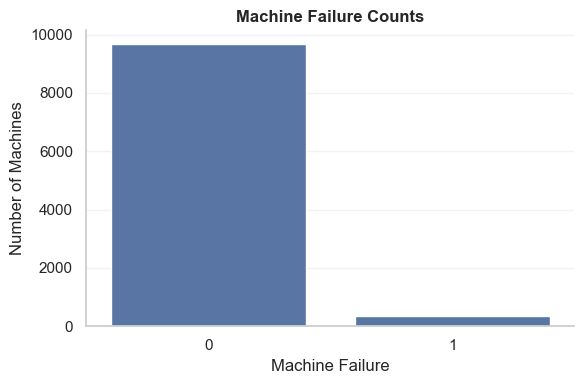

In [61]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Machine failure", data=df)

plt.title("Machine Failure Counts")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Machines")
plt.tight_layout()
plt.savefig(images_dir / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### Sensor Readings and Machine Failure

The boxplots compare five sensor measurements for failure and nonfailure observations. Failure observations generally have higher tool wear and torque and a lower median rotational speed, but the groups still overlap. No single measurement cleanly separates all failures.
The following heatmap shows pairwise linear correlations. Air and process temperature are strongly related, while torque and speed have a strong negative relationship. These associations do not establish cause and effect or capture every interaction a Random Forest can use.

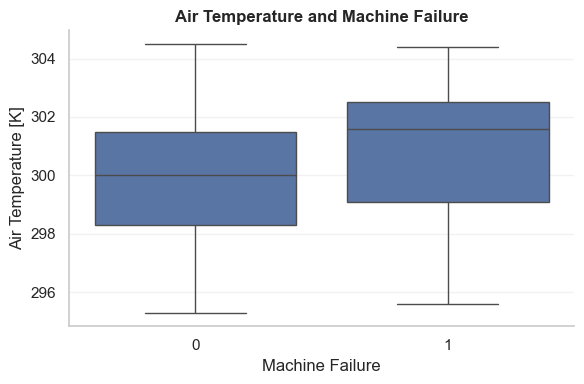

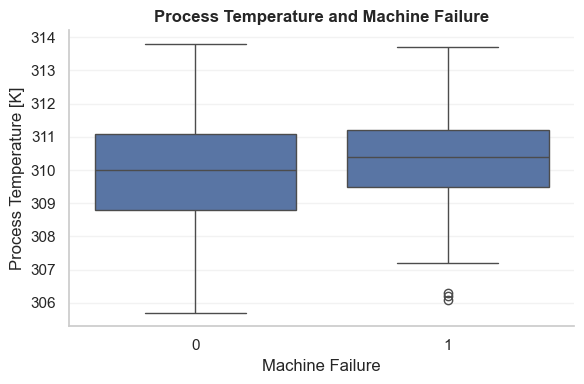

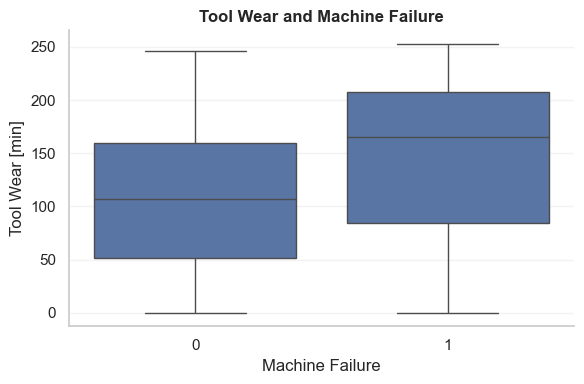

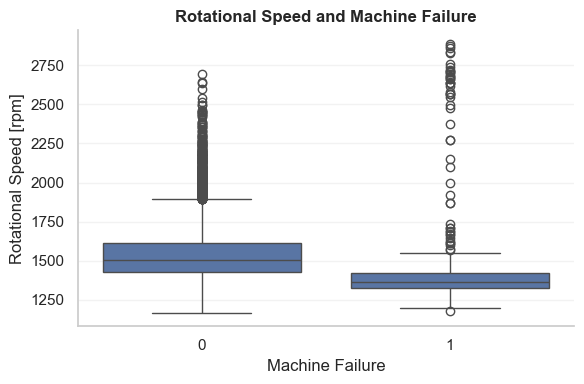

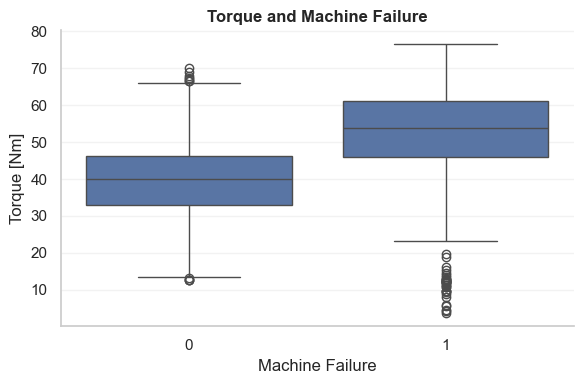

In [62]:
# Air temperature
plt.figure(figsize=(6, 4))
sns.boxplot(x="Machine failure", y="Air temperature [K]", data=df)
plt.title("Air Temperature and Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Air Temperature [K]")
plt.tight_layout()
plt.savefig(images_dir / "air_temperature_by_failure.png", dpi=150, bbox_inches="tight")
plt.show()

# Process temperature
plt.figure(figsize=(6, 4))
sns.boxplot(x="Machine failure", y="Process temperature [K]", data=df)
plt.title("Process Temperature and Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Process Temperature [K]")
plt.tight_layout()
plt.savefig(images_dir / "process_temperature_by_failure.png", dpi=150, bbox_inches="tight")
plt.show()

# Tool wear
plt.figure(figsize=(6, 4))
sns.boxplot(x="Machine failure", y="Tool wear [min]", data=df)
plt.title("Tool Wear and Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Tool Wear [min]")
plt.tight_layout()
plt.savefig(images_dir / "tool_wear_by_failure.png", dpi=150, bbox_inches="tight")
plt.show()

# Rotational speed
plt.figure(figsize=(6, 4))
sns.boxplot(x="Machine failure", y="Rotational speed [rpm]", data=df)
plt.title("Rotational Speed and Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Rotational Speed [rpm]")
plt.tight_layout()
plt.savefig(images_dir / "rotational_speed_by_failure.png", dpi=150, bbox_inches="tight")
plt.show()

# Torque
plt.figure(figsize=(6, 4))
sns.boxplot(x="Machine failure", y="Torque [Nm]", data=df)
plt.title("Torque and Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Torque [Nm]")
plt.tight_layout()
plt.savefig(images_dir / "torque_by_failure.png", dpi=150, bbox_inches="tight")
plt.show()


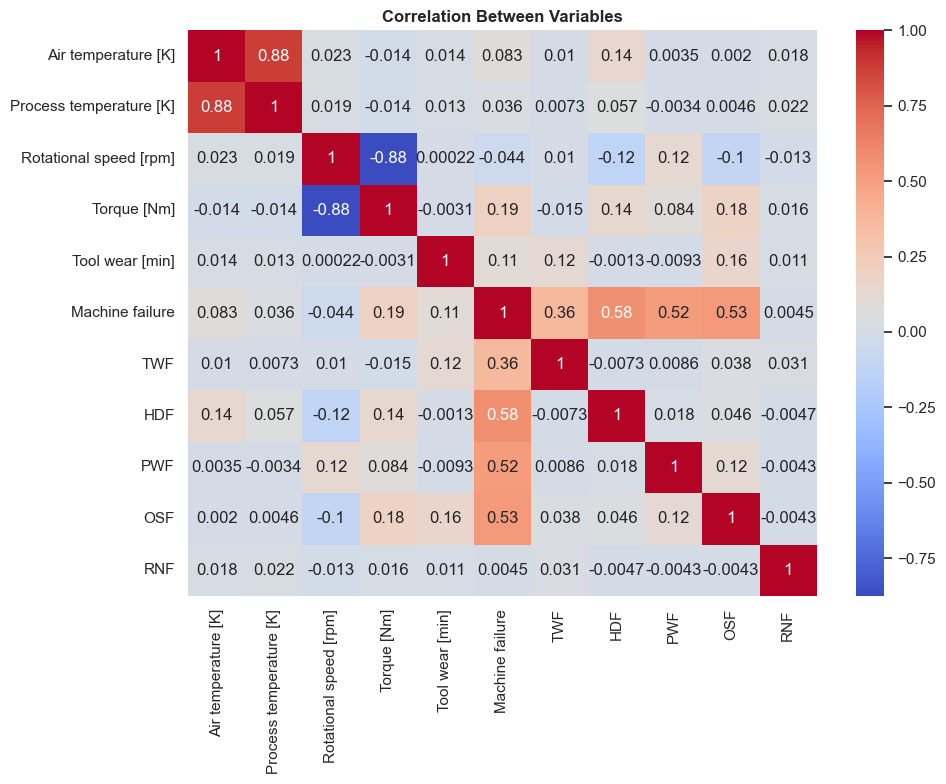

In [63]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Between Variables")
plt.tight_layout()
plt.savefig(images_dir / "sensor_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Prepare the Model Inputs

The target is Machine failure. I exclude TWF, HDF, PWF, OSF, and RNF from the predictors because they describe failure outcomes and could reveal the answer. I encode product Type using H as the reference category and two indicators for L and M. Together with five sensor inputs, this gives the MVP seven features. I use an 80/20 stratified split with a random seed of 42. This gives 8,000 training observations and 2,000 test observations, including 68 test failures. All models use the same test observations. Scaling and parameter selection use training data only. The source includes time-related patterns, so the random split may place similar observations in both groups. The test set has also been examined during development. A fresh time-based or external evaluation is still needed.

In [64]:
# Product categories are fixed by the dataset definition.
df["Type"] = pd.Categorical(df["Type"], categories=["H", "L", "M"])
df_model = pd.get_dummies(
    df,
    columns=["Type"],
    drop_first=True,
    dtype=int
)

y = df_model["Machine failure"]

X = df_model.drop(columns=[
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Number of model features:", X.shape[1])
print("\nFeatures:")
print(X.columns.tolist())

print("\nTraining rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training failures:", int(y_train.sum()))
print("Test failures:", int(y_test.sum()))

Number of model features: 7

Features:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_L', 'Type_M']

Training rows: 8000
Test rows: 2000
Training failures: 271
Test failures: 68


In [65]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)

logistic_accuracy = accuracy_score(
    y_test, logistic_predictions
)

logistic_precision = precision_score(
    y_test, logistic_predictions, zero_division=0
)

logistic_recall = recall_score(
    y_test, logistic_predictions, zero_division=0
)

logistic_f1 = f1_score(
    y_test, logistic_predictions, zero_division=0
)

print("LOGISTIC REGRESSION RESULTS")
print(f"Accuracy:  {logistic_accuracy:.3f}")
print(f"Precision: {logistic_precision:.3f}")
print(f"Recall:    {logistic_recall:.3f}")
print(f"F1 Score:  {logistic_f1:.3f}")

LOGISTIC REGRESSION RESULTS
Accuracy:  0.825
Precision: 0.142
Recall:    0.824
F1 Score:  0.242


## 5. Reference Model — Logistic Regression

Logistic Regression provides a simple linear comparison. I fit the scaler on training data only and use balanced class weights because failures are rare. In the verified run, accuracy was 0.825, precision was 0.142, recall was 0.824, and F1 was 0.242. The model detected 56 of 68 failures, missed 12, and produced 339 false alerts. It catches many failures, but most alerts are incorrect. This could create too much inspection work, so high recall alone does not make it the best model.

In [66]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

random_forest.fit(X_train, y_train)

rf_predictions = random_forest.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

rf_precision = precision_score(
    y_test, rf_predictions, zero_division=0
)

rf_recall = recall_score(
    y_test, rf_predictions, zero_division=0
)

rf_f1 = f1_score(
    y_test, rf_predictions, zero_division=0
)

print("MVP RANDOM FOREST RESULTS")
print(f"Accuracy:  {rf_accuracy:.3f}")
print(f"Precision: {rf_precision:.3f}")
print(f"Recall:    {rf_recall:.3f}")
print(f"F1 Score:  {rf_f1:.3f}")

MVP RANDOM FOREST RESULTS
Accuracy:  0.981
Precision: 0.734
Recall:    0.691
F1 Score:  0.712


## 6. MVP Baseline — Random Forest

The original Random Forest is the MVP baseline. It uses 100 trees, balanced class weights, and a random seed of 42. The MVP achieved accuracy of 0.981, precision of 0.734, recall of 0.691, and F1 of 0.712. It detected 47 of the 68 test failures, missed 21, and produced 17 false alerts. Compared with Logistic Regression, the MVP produces far fewer false alerts and has a higher F1 score. However, its lower recall means it misses more actual failures. This tradeoff matters because missed failures could lead to downtime, repair costs, or safety problems. The MVP provides the comparison point for the improved model.

In [67]:
baseline_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "MVP Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall
    ],
    "F1 Score": [
        logistic_f1,
        rf_f1
    ]
})

print(baseline_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

print("\nMVP RANDOM FOREST CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    rf_predictions,
    labels=[0, 1],
    target_names=["No failure", "Failure"],
    zero_division=0
))

              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression     0.825      0.142   0.824     0.242
  MVP Random Forest     0.981      0.734   0.691     0.712

MVP RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

  No failure       0.99      0.99      0.99      1932
     Failure       0.73      0.69      0.71        68

    accuracy                           0.98      2000
   macro avg       0.86      0.84      0.85      2000
weighted avg       0.98      0.98      0.98      2000



## 7. Improved Random Forest

The improved model builds on the MVP Random Forest by adding two features and testing different model settings.

| Feature | Calculation | Reason |
|---|---|---|
| Temperature difference | Process temperature minus air temperature | Represents the temperature gap related to heat dissipation |
| Power proxy | Torque multiplied by rotational speed | Represents the combined effect of load and speed |

The power proxy uses torque multiplied by rpm, so it is not measured in watts. These features combine information that the original model received as separate inputs. This may make useful relationships easier for the model to identify. I removed the earlier high-tool-wear flag because its cutoff was calculated using the full dataset, including test observations. It also repeated information already available in the continuous tool-wear feature. The two retained features use formulas that do not learn statistics from the test data.

I tested eight Random Forest configurations using three stratified cross-validation folds within the training data. The search compared:

- 150 or 300 trees.
- A maximum depth of 10 or unlimited depth.
- A minimum leaf size of 1 or 3.

F1 was used to select the settings because the project needs to balance failure detection and false alerts. The selected model used 300 trees, unlimited maximum depth, and a minimum leaf size of 1. Its mean training cross-validation F1 was 0.806. The selected model was then evaluated on the same test observations as the reference model and MVP. Feature engineering and tuning were changed together, so this comparison does not show how much each change helped separately.

In [76]:
def add_engineered_features(features):
    """Add two features without changing the original inputs.

    Input:
        features: A DataFrame containing encoded sensor and product inputs.

    Returns:
        A copy with temperature difference and a torque-times-rpm power proxy.
        The original row index is preserved. The proxy is not in watts.
    """
    engineered = features.copy()
    engineered["Temperature difference [K]"] = (
        engineered["Process temperature [K]"] - engineered["Air temperature [K]"]
    )
    engineered["Power proxy"] = (
        engineered["Torque [Nm]"] * engineered["Rotational speed [rpm]"]
    )
    return engineered


X_engineered = add_engineered_features(X)

# Use the same observations as the original train/test split.
X_train_eng = X_engineered.loc[X_train.index].copy()
X_test_eng = X_engineered.loc[X_test.index].copy()

print("Original features:", X_train.shape[1])
print("Improved features:", X_train_eng.shape[1])

Original features: 7
Improved features: 9


In [83]:
param_grid = {
    "n_estimators": [150, 300],
    "max_depth": [10, None],
    "min_samples_leaf": [1, 3]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

tuned_rf_search = GridSearchCV(
    RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1
)

# Choose settings using training data only.
tuned_rf_search.fit(X_train_eng, y_train)

tuned_random_forest = tuned_rf_search.best_estimator_

pd.DataFrame(tuned_rf_search.cv_results_).to_csv(
    results_dir / "cross_validation.csv",
    index=False
)

best_settings = tuned_rf_search.best_params_

max_depth = best_settings["max_depth"]
if max_depth is None:
    max_depth = "Unlimited"

print("IMPROVED RANDOM FOREST SETTINGS")
print("-" * 35)
print(f"{'Number of trees:':<24}{best_settings['n_estimators']}")
print(f"{'Maximum depth:':<24}{max_depth}")
print(f"{'Minimum leaf size:':<24}{best_settings['min_samples_leaf']}")
print(f"{'Cross-validation F1:':<24}{tuned_rf_search.best_score_:.3f}")

IMPROVED RANDOM FOREST SETTINGS
-----------------------------------
Number of trees:        300
Maximum depth:          Unlimited
Minimum leaf size:      1
Cross-validation F1:    0.806


## 8. Final Model Comparison

All three models are evaluated on the same test observations using the default 0.5 probability threshold.

| Model | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.825 | 0.142 | 0.824 | 0.242 |
| MVP Random Forest | 0.981 | 0.734 | 0.691 | 0.712 |
| Improved Random Forest | 0.991 | 0.917 | 0.809 | 0.859 |

The improved Random Forest has the highest F1 score at 0.859, compared with 0.712 for the MVP. It also improves both precision and recall over the MVP. Its precision of 0.917 means about 91.7% of its failure alerts are correct. Its recall of 0.809 means it detects about 80.9% of actual failures. Logistic Regression still has slightly higher recall, but it produces many more false alerts. The improved Random Forest provides the strongest balance between finding failures and keeping false alerts low on this test set. These results support choosing the improved Random Forest for this project. They do not establish that it is ready for real maintenance decisions.

In [78]:
def evaluate_model(name, y_true, predictions, probabilities):
    """Calculate model scores and error counts.

    Inputs:
        name: Model name.
        y_true: Actual binary failure labels.
        predictions: Predicted binary failure labels.
        probabilities: Predicted probabilities of failure.
        All arrays must have matching observation order.

    Returns:
        A dictionary with accuracy, precision, recall, F1, ROC-AUC,
        and TN, FP, FN, TP counts. Failure is the positive class.
    """
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)
    }


logistic_probabilities = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

baseline_rf_probabilities = random_forest.predict_proba(
    X_test
)[:, 1]

tuned_rf_predictions = tuned_random_forest.predict(
    X_test_eng
)

tuned_rf_probabilities = tuned_random_forest.predict_proba(
    X_test_eng
)[:, 1]

final_results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_predictions,
        logistic_probabilities
    ),
    evaluate_model(
        "MVP Random Forest",
        y_test,
        rf_predictions,
        baseline_rf_probabilities
    ),
    evaluate_model(
        "Improved Random Forest",
        y_test,
        tuned_rf_predictions,
        tuned_rf_probabilities
    )
])

final_results.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

print("FINAL MODEL COMPARISON")
print(final_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

FINAL MODEL COMPARISON
                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC   TN  FP  FN  TP
   Logistic Regression     0.825      0.142   0.824     0.242    0.907 1593 339  12  56
     MVP Random Forest     0.981      0.734   0.691     0.712    0.960 1915  17  21  47
Improved Random Forest     0.991      0.917   0.809     0.859    0.970 1927   5  13  55


### Model Comparison

Logistic Regression detects 56 of the 68 failures, giving it the highest recall at 0.824. However, it produces 339 false alerts. Its precision of 0.142 means only about 14.2% of its failure alerts are correct. Although it catches many failures, the large number of incorrect alerts could create an unreasonable inspection workload. The MVP Random Forest greatly reduces false alerts, from 339 to 17. Its precision rises to 0.734, and its F1 improves from 0.242 to 0.712. However, it detects only 47 failures and misses 21. This shows that reducing false alerts comes with lower failure detection compared with Logistic Regression. The improved Random Forest provides the strongest overall balance. It detects 55 failures, misses 13, and produces only 5 false alerts. Compared with the MVP, it detects 8 additional failures while producing 12 fewer false alerts. Its F1 increases from 0.712 to 0.859. Compared with Logistic Regression, it misses only one additional failure while producing 334 fewer false alerts. Based on these results, the improved Random Forest is the strongest model for this project. A real maintenance decision would still require information about the costs of missed failures, inspection capacity, and acceptable alert volume.

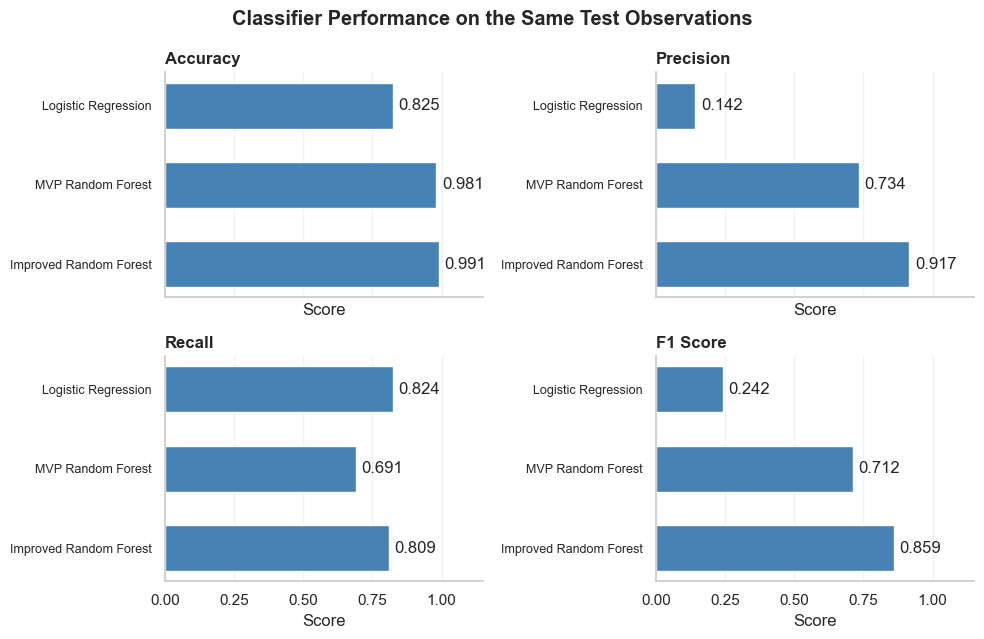

In [79]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
model_names = final_results["Model"].tolist()
for ax, metric in zip(axes.flat, ["Accuracy", "Precision", "Recall", "F1 Score"]):
    values = final_results[metric].to_numpy()
    bars = ax.barh(model_names, values, color="steelblue", height=0.58)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.15)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.set_title(metric, loc="left")
    ax.set_xlabel("Score")
    ax.bar_label(bars, labels=[f"{value:.3f}" for value in values], padding=4)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=9)
fig.suptitle("Classifier Performance on the Same Test Observations", fontweight="bold")
plt.tight_layout()
plt.savefig(images_dir / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

### Refined Confusion Matrix

The confusion matrix shows how the improved Random Forest performed on the 2,000 test observations. Rows represent actual status, and columns represent predicted status.

| Actual status | Predicted no failure | Predicted failure |
|---|---:|---:|
| No failure | 1,927 | 5 |
| Failure | 13 | 55 |

The model correctly identifies 1,927 nonfailure observations and 55 failure observations. The 5 observations in the upper-right cell are false alerts. These machines did not fail, but the model predicted failure. These alerts could lead to unnecessary inspections or maintenance. The 13 observations in the lower-left cell are missed failures. These machines failed, but the model predicted no failure. These errors are especially important because they could leave maintenance teams without an alert before a problem is addressed. The model detects 55 of the 68 failures, giving it recall of 0.809. It produces 60 failure alerts in total, and 55 are correct, giving it precision of 0.917. Its overall accuracy is 0.991, but that number alone hides the 13 missed failures. The confusion matrix makes those remaining errors clear. Compared with the MVP, the improved model reduces missed failures from 21 to 13 and false alerts from 17 to 5. It improves both types of error, although it still does not detect every failure.

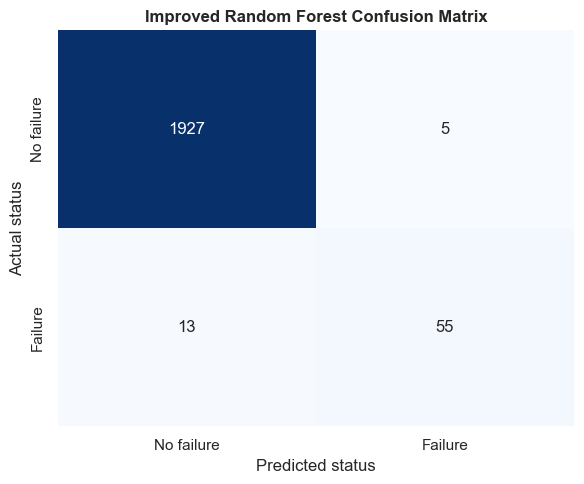

Correct nonfailure predictions: 1927
False alerts: 5
Missed failures: 13
Detected failures: 55


In [80]:
refined_cm = confusion_matrix(
    y_test, tuned_rf_predictions, labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    refined_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["No failure", "Failure"],
    yticklabels=["No failure", "Failure"]
)
plt.title("Improved Random Forest Confusion Matrix")
plt.xlabel("Predicted status")
plt.ylabel("Actual status")
plt.tight_layout()
plt.savefig(images_dir / "refined_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Correct nonfailure predictions:", refined_cm[0, 0])
print("False alerts:", refined_cm[0, 1])
print("Missed failures:", refined_cm[1, 0])
print("Detected failures:", refined_cm[1, 1])

### Refined Feature Importance

The chart shows how strongly the improved Random Forest used each of its nine inputs to reduce impurity when separating observations. Tool wear and rotational speed have the highest importance, each at approximately 0.219. Torque follows at approximately 0.201. Together, these three features account for about 64% of the model's total impurity-based importance. This indicates that the fitted model relies heavily on information about wear, speed, and load when distinguishing failure from nonfailure observations. The added power proxy has an importance of approximately 0.190, making it the fourth-highest feature. The temperature-difference feature has an importance of approximately 0.086, placing it fifth. Both engineered features are used by the improved model. The power proxy combines torque and speed, while temperature difference represents the gap between process and air temperature. Their rankings suggest these combinations help the model separate observations, but the rankings alone do not prove that adding them caused the improvement in F1. Air temperature, process temperature, and the product-type indicators have lower importance in this fitted model. Lower importance does not mean they are useless. Some of their information may overlap with the engineered features or other inputs. These scores are not failure probabilities or proof of cause and effect. Impurity-based importance can favor continuous features and distribute importance across correlated inputs. A future permutation-importance check would provide another way to examine the rankings.

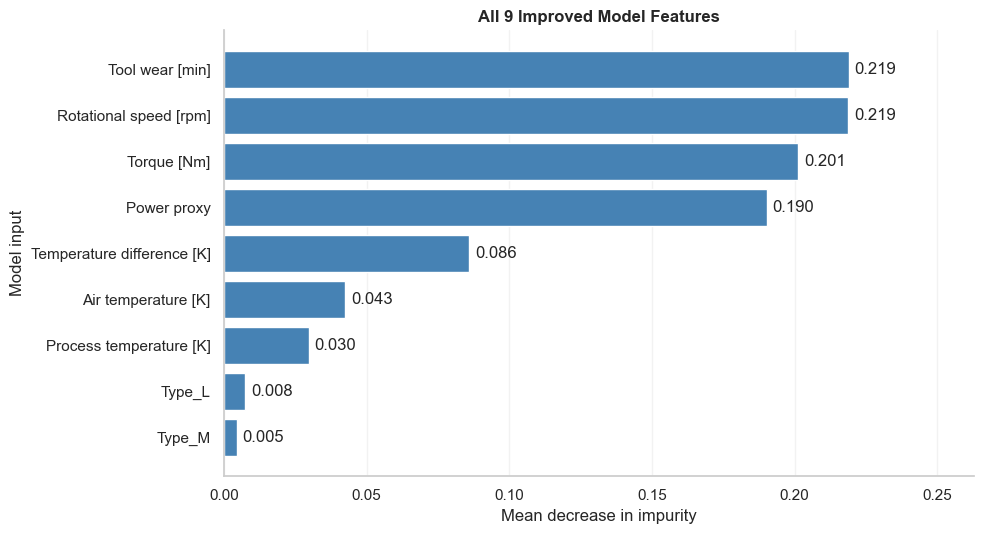

                   Feature  Importance
           Tool wear [min]      0.2190
    Rotational speed [rpm]      0.2188
               Torque [Nm]      0.2013
               Power proxy      0.1903
Temperature difference [K]      0.0860
       Air temperature [K]      0.0426
   Process temperature [K]      0.0298
                    Type_L      0.0075
                    Type_M      0.0046


In [81]:
refined_importance = pd.DataFrame({
    "Feature": X_engineered.columns,
    "Importance": tuned_random_forest.feature_importances_
}).sort_values("Importance", ascending=False)
refined_importance.to_csv(results_dir / "feature_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(refined_importance["Feature"], refined_importance["Importance"],
               color="steelblue")
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{v:.3f}" for v in refined_importance["Importance"]], padding=4)
ax.set_xlim(0, refined_importance["Importance"].max() * 1.2)
ax.set(title=f"All {len(refined_importance)} Improved Model Features",
       xlabel="Mean decrease in impurity", ylabel="Model input")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(images_dir / "refined_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(refined_importance.round(4).to_string(index=False))

## 9. Results

The improved Random Forest provides the strongest balance between detecting failures and limiting false alerts on this development test set. Its F1 score is 0.859, compared with 0.712 for the MVP. Precision improves from 0.734 to 0.917, while recall improves from 0.691 to 0.809. This means the improved model's alerts are more reliable, and it also detects a larger share of actual failures. The improved model correctly identifies 55 of the 68 test failures and misses 13. Compared with the MVP, it detects 8 additional failures and reduces false alerts from 17 to 5. Logistic Regression detects one more failure than the improved Random Forest, but it produces 339 false alerts compared with only 5. The improved Random Forest therefore achieves nearly the same failure detection with a much smaller alert workload. For maintenance teams, fewer missed failures could help reduce unexpected downtime, repairs, and safety exposure. Fewer false alerts could also reduce unnecessary inspections. However, these are possible benefits rather than measured outcomes because the dataset does not include maintenance costs or actual savings. The remaining 13 missed failures show that the model is not a complete decision system. Choosing a different alert threshold might detect more failures, but it could also increase false alerts. That tradeoff should be tested using training or validation data and realistic maintenance priorities. The results support selecting the improved Random Forest for this project. However, the data is synthetic, the test set has already been examined during development, and the random split does not prove future performance. Testing records in time order and using fresh real-machine data are still needed before making stronger claims.

In [82]:
baseline_f1 = final_results.loc[
    final_results["Model"] == "MVP Random Forest",
    "F1 Score"
].iloc[0]

improved_f1 = final_results.loc[
    final_results["Model"] == "Improved Random Forest",
    "F1 Score"
].iloc[0]

best_model = final_results.loc[
    final_results["F1 Score"].idxmax(),
    "Model"
]

print("PROJECT RESULTS")
print(f"\nMVP Random Forest F1: {baseline_f1:.3f}")
print(f"Improved Random Forest F1: {improved_f1:.3f}")

if improved_f1 > baseline_f1:
    print(
        "The improved model has a better balance "
        "of precision and recall based on F1."
    )
else:
    print(
        "The changes did not improve F1 over the MVP."
    )

print("\nHighest test F1:", best_model)

print(
    f"\nThe improved model detected "
    f"{refined_cm[1, 1]} of {int(y_test.sum())} failures."
)

print("Missed failures:", refined_cm[1, 0])
print("False alerts:", refined_cm[0, 1])

print(
    "\nMissed failures may lead to downtime, "
    "repair costs, or safety problems."
)

print(
    "False alerts may lead to unnecessary "
    "inspections or maintenance."
)

print("\nThree most important model inputs:")

print(
    refined_importance.head(3)
    .round(3)
    .to_string(index=False)
)

PROJECT RESULTS

MVP Random Forest F1: 0.712
Improved Random Forest F1: 0.859
The improved model has a better balance of precision and recall based on F1.

Highest test F1: Improved Random Forest

The improved model detected 55 of 68 failures.
Missed failures: 13
False alerts: 5

Missed failures may lead to downtime, repair costs, or safety problems.
False alerts may lead to unnecessary inspections or maintenance.

Three most important model inputs:
               Feature  Importance
       Tool wear [min]       0.219
Rotational speed [rpm]       0.219
           Torque [Nm]       0.201


## 10. Feedback Addressed

No feedback given this week

## 11. Limitations and Next Steps

The data is synthetic, and the test set contains only 68 failures. The random split may place similar time-related patterns in both groups, and the test set has already been examined during development. These factors limit claims about future or real-world performance.

Future improvements include time-based and external validation, uncertainty estimates, threshold selection based on maintenance costs, and separate tests of feature engineering and tuning. These are extensions of the completed analysis.

This notebook uses a local CSV path. Someone running it elsewhere must download the dataset and update that path as explained in the README.